##Project Roadmap

0. Setup & Imports
1. Data Understanding
2. Statistical analysis
3. Data Cleaning
4. Univariate Analysis
5. Bivariate Analysis
6. Multivariate Analysis
7. Outlier Analysis (Deep Dive)
8. Key Insights & Conclusion

Step 1 — Check your virtual environment
In your VS Code terminal, paste:
Test-Path .\.venv\Scripts\python.exe


Press Enter.
- If you see True, continue to Step 2.
- If you see False, run this command to create the environment:
& "C:\Users\hp\.local\bin\python3.14.exe" -m venv .venv


Step 2 — Install the required libraries
Paste this single command in your terminal:
.\.venv\Scripts\python.exe -m pip install ipykernel pandas numpy matplotlib seaborn scipy scikit-learn


Press Enter and wait for installation to complete.
If the error says No module named pip, run:
.\.venv\Scripts\python.exe -m ensurepip --upgrade


Then repeat the installation command above.
Step 3 — Select the correct Python kernel
In your VS Code notebook:
1. Click Select Kernel at the top-right.
2. Click Python Environments.
3. Select the Python interpreter inside your project's .venv folder.
4. If it isn't listed, use Select Interpreter Path and locate .venv\Scripts\python.exe.
This is important because your screenshot shows VS Code is still trying to run the other Python 3.14.6 installation.

## 0. Setup & Imports

In [1]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

print("All libraries are working!")

All libraries are working!


In [2]:
df=pd.read_csv("fetal_health.csv")

df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [3]:
df.head(1)

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0


In [4]:
df.tail()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
2121,140.0,0.000,0.000,0.007,0.0,0.0,0.0,79.0,0.2,25.0,...,137.0,177.0,4.0,0.0,153.0,150.0,152.0,2.0,0.0,2.0
2122,140.0,0.001,0.000,0.007,0.0,0.0,0.0,78.0,0.4,22.0,...,103.0,169.0,6.0,0.0,152.0,148.0,151.0,3.0,1.0,2.0
2123,140.0,0.001,0.000,0.007,0.0,0.0,0.0,79.0,0.4,20.0,...,103.0,170.0,5.0,0.0,153.0,148.0,152.0,4.0,1.0,2.0
2124,140.0,0.001,0.000,0.006,0.0,0.0,0.0,78.0,0.4,27.0,...,103.0,169.0,6.0,0.0,152.0,147.0,151.0,4.0,1.0,2.0
2125,142.0,0.002,0.002,0.008,0.0,0.0,0.0,74.0,0.4,36.0,...,117.0,159.0,2.0,1.0,145.0,143.0,145.0,1.0,0.0,1.0


In [5]:
df.shape

(2126, 22)

In [6]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Shape: 2126 rows x 22 columns


## 1. Data Understanding

1.1 Structure & Data Types

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [8]:
df.columns

Index(['baseline value', 'accelerations', 'fetal_movement',
       'uterine_contractions', 'light_decelerations', 'severe_decelerations',
       'prolongued_decelerations', 'abnormal_short_term_variability',
       'mean_value_of_short_term_variability',
       'percentage_of_time_with_abnormal_long_term_variability',
       'mean_value_of_long_term_variability', 'histogram_width',
       'histogram_min', 'histogram_max', 'histogram_number_of_peaks',
       'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean',
       'histogram_median', 'histogram_variance', 'histogram_tendency',
       'fetal_health'],
      dtype='str')

In [9]:
df.columns.tolist()

['baseline value',
 'accelerations',
 'fetal_movement',
 'uterine_contractions',
 'light_decelerations',
 'severe_decelerations',
 'prolongued_decelerations',
 'abnormal_short_term_variability',
 'mean_value_of_short_term_variability',
 'percentage_of_time_with_abnormal_long_term_variability',
 'mean_value_of_long_term_variability',
 'histogram_width',
 'histogram_min',
 'histogram_max',
 'histogram_number_of_peaks',
 'histogram_number_of_zeroes',
 'histogram_mode',
 'histogram_mean',
 'histogram_median',
 'histogram_variance',
 'histogram_tendency',
 'fetal_health']

## 2. Statistical analysis

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
baseline value,2126.0,133.303857,9.840844,106.0,126.000,133.000,140.000,160.000
accelerations,2126.0,0.003178,0.003866,0.0,0.000,0.002,0.006,0.019
fetal_movement,2126.0,0.009481,0.046666,0.0,0.000,0.000,0.003,0.481
uterine_contractions,2126.0,0.004366,0.002946,0.0,0.002,0.004,0.007,0.015
light_decelerations,2126.0,0.001889,0.002960,0.0,0.000,0.000,0.003,0.015
severe_decelerations,2126.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
prolongued_decelerations,2126.0,0.000159,0.000590,0.0,0.000,0.000,0.000,0.005
abnormal_short_term_variability,2126.0,46.990122,17.192814,12.0,32.000,49.000,61.000,87.000
mean_value_of_short_term_variability,2126.0,1.332785,0.883241,0.2,0.700,1.200,1.700,7.000
percentage_of_time_with_abnormal_long_term_variability,2126.0,9.846660,18.396880,0.0,0.000,0.000,11.000,91.000


- Data cleaning


1.4 Missing Values Overview

In [11]:
df.dtypes

baseline value                                            float64
accelerations                                             float64
fetal_movement                                            float64
uterine_contractions                                      float64
light_decelerations                                       float64
severe_decelerations                                      float64
prolongued_decelerations                                  float64
abnormal_short_term_variability                           float64
mean_value_of_short_term_variability                      float64
percentage_of_time_with_abnormal_long_term_variability    float64
mean_value_of_long_term_variability                       float64
histogram_width                                           float64
histogram_min                                             float64
histogram_max                                             float64
histogram_number_of_peaks                                 float64
histogram_

In [12]:
df.duplicated().sum()

np.int64(13)

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df.shape

(2113, 22)

In [15]:
df.isnull()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2121,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2122,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2123,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2124,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [16]:
df.isnull().sum()

baseline value                                            0
accelerations                                             0
fetal_movement                                            0
uterine_contractions                                      0
light_decelerations                                       0
severe_decelerations                                      0
prolongued_decelerations                                  0
abnormal_short_term_variability                           0
mean_value_of_short_term_variability                      0
percentage_of_time_with_abnormal_long_term_variability    0
mean_value_of_long_term_variability                       0
histogram_width                                           0
histogram_min                                             0
histogram_max                                             0
histogram_number_of_peaks                                 0
histogram_number_of_zeroes                                0
histogram_mode                          

In [17]:
# if null values more than 25% values , i was removed that column
df.isnull().sum()/df.shape[0]*100

baseline value                                            0.0
accelerations                                             0.0
fetal_movement                                            0.0
uterine_contractions                                      0.0
light_decelerations                                       0.0
severe_decelerations                                      0.0
prolongued_decelerations                                  0.0
abnormal_short_term_variability                           0.0
mean_value_of_short_term_variability                      0.0
percentage_of_time_with_abnormal_long_term_variability    0.0
mean_value_of_long_term_variability                       0.0
histogram_width                                           0.0
histogram_min                                             0.0
histogram_max                                             0.0
histogram_number_of_peaks                                 0.0
histogram_number_of_zeroes                                0.0
histogra

- filling null/missing values rules

mean : if don't have outliers

median : if we have outliers

mode : filling text column , with most repeated value

In [18]:
df["baseline value"]=df["baseline value"].fillna(df["baseline value"].mean())

In [19]:
df['accelerations']=df['accelerations'].fillna(df['accelerations'].mean())

In [20]:
df["fetal_movement"]=df["fetal_movement"].fillna(df['fetal_movement'].mean())

In [21]:
df.fetal_health = df.fetal_health.fillna(df.fetal_health.mean())

In [22]:
df.head(13)

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.000,0.000,0.000,0.0,0.000,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.000,0.006,0.003,0.0,0.000,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.000,0.008,0.003,0.0,0.000,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.000,0.008,0.003,0.0,0.000,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.000,0.008,0.000,0.0,0.000,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0
5,134.0,0.001,0.000,0.010,0.009,0.0,0.002,26.0,5.9,0.0,...,50.0,200.0,5.0,3.0,76.0,107.0,107.0,170.0,0.0,3.0
6,134.0,0.001,0.000,0.013,0.008,0.0,0.003,29.0,6.3,0.0,...,50.0,200.0,6.0,3.0,71.0,107.0,106.0,215.0,0.0,3.0
7,122.0,0.000,0.000,0.000,0.000,0.0,0.000,83.0,0.5,6.0,...,62.0,130.0,0.0,0.0,122.0,122.0,123.0,3.0,1.0,3.0
8,122.0,0.000,0.000,0.002,0.000,0.0,0.000,84.0,0.5,5.0,...,62.0,130.0,0.0,0.0,122.0,122.0,123.0,3.0,1.0,3.0
9,122.0,0.000,0.000,0.003,0.000,0.0,0.000,86.0,0.3,6.0,...,62.0,130.0,1.0,0.0,122.0,122.0,123.0,1.0,1.0,3.0


In [23]:
df.histogram_number_of_peaks = df.histogram_number_of_peaks.fillna(df.histogram_number_of_peaks.mode()[0])

In [24]:
df.histogram_number_of_zeroes=df.histogram_number_of_zeroes.fillna(df.histogram_number_of_zeroes.median())

In [25]:
df.isnull().sum()

baseline value                                            0
accelerations                                             0
fetal_movement                                            0
uterine_contractions                                      0
light_decelerations                                       0
severe_decelerations                                      0
prolongued_decelerations                                  0
abnormal_short_term_variability                           0
mean_value_of_short_term_variability                      0
percentage_of_time_with_abnormal_long_term_variability    0
mean_value_of_long_term_variability                       0
histogram_width                                           0
histogram_min                                             0
histogram_max                                             0
histogram_number_of_peaks                                 0
histogram_number_of_zeroes                                0
histogram_mode                          

In [26]:
df["baseline value"].value_counts()

baseline value
133.0    136
130.0    111
122.0    106
138.0    102
125.0     91
128.0     85
120.0     78
142.0     77
132.0     76
144.0     76
136.0     72
140.0     69
134.0     67
135.0     64
146.0     61
127.0     60
137.0     59
129.0     57
131.0     56
143.0     56
123.0     53
148.0     51
121.0     44
141.0     39
139.0     39
126.0     38
145.0     36
115.0     28
150.0     26
110.0     21
149.0     18
119.0     17
152.0     17
112.0     16
151.0     14
147.0     14
159.0     12
114.0     11
124.0     10
158.0     10
118.0      9
154.0      8
106.0      7
116.0      5
156.0      4
157.0      4
117.0      2
160.0      1
Name: count, dtype: int64

2.1 Fix Inconsistent Categorical Labels


2.2 Remove Duplicate Rows

In [27]:
before = len(df)
df = df.drop_duplicates(subset='baseline value', keep='first').reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. New shape: {df.shape}")


Removed 2065 duplicate rows. New shape: (48, 22)


2.3 Fix Invalid Values


Negative deceleration is not physically meaningful — we take the absolute value (a common data-entry sign error) rather than dropping the rows.

In [28]:
neg_deceleration_count = (df['prolongued_decelerations'] < 0).sum()
print(f"Negative deceleration rows: {neg_deceleration_count}")
df['prolongued_decelerations'] = df['prolongued_decelerations'].abs()

Negative deceleration rows: 0



2.4 Handle Outliers (IQR Method)

We cap physiologically impossible values instead of deleting rows, to preserve sample size. 'histogram_width' above 100 and 'histogram_min', 'histogram_max' far beyond clinical extremes are capped at the 99th percentile (winsorization).

In [29]:
def cap_outliers_iqr(series, factor=1.5):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - factor * IQR, Q3 + factor * IQR
    return series.clip(lower=lower, upper=upper), lower, upper

for col in ['histogram_width', 'histogram_min', 'histogram_max']:
    before_max = df[col].max()
    df[col], low, up = cap_outliers_iqr(df[col])
    print(f"{col}: capped to [{low:.1f}, {up:.1f}]  (was max {before_max:.1f}, now max {df[col].max():.1f})")

histogram_width: capped to [-26.0, 218.0]  (was max 150.0, now max 150.0)
histogram_min: capped to [3.1, 146.1]  (was max 153.0, now max 146.1)
histogram_max: capped to [107.9, 232.9]  (was max 205.0, now max 205.0)


2.5 Handle Missing Values

In [30]:
numeric_missing = ['baseline value','accelerations','fetal_movement','uterine_contractions']
categorical_missing = ['histogram_number_of_peaks','histogram_number_of_zeroes']

for col in numeric_missing:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)
    print(f"Filled missing values in {col} with median: {median_value}")

for col in categorical_missing:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)
    print(f"Filled missing values in {col} with mode: {mode_value}")
    

Filled missing values in baseline value with median: 134.5
Filled missing values in accelerations with median: 0.002
Filled missing values in fetal_movement with median: 0.0
Filled missing values in uterine_contractions with median: 0.004
Filled missing values in histogram_number_of_peaks with mode: 2.0
Filled missing values in histogram_number_of_zeroes with mode: 0.0


2.6 Correct Data Types & Add Derived Categories

In [31]:
df['baseline value'] = df['baseline value'].round(2).astype(int)
df['accelerations'] = df['accelerations'].round(2).astype(int)

for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].round(2)

df.dtypes

baseline value                                              int64
accelerations                                               int64
fetal_movement                                            float64
uterine_contractions                                      float64
light_decelerations                                       float64
severe_decelerations                                      float64
prolongued_decelerations                                  float64
abnormal_short_term_variability                           float64
mean_value_of_short_term_variability                      float64
percentage_of_time_with_abnormal_long_term_variability    float64
mean_value_of_long_term_variability                       float64
histogram_width                                           float64
histogram_min                                             float64
histogram_max                                             float64
histogram_number_of_peaks                                 float64
histogram_

2.7 Sanity Check After Cleaning

In [33]:
print("Shape:", df.shape)
print("Missing values total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T

Shape: (48, 22)
Missing values total: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
baseline value,48.0,134.562500,14.657663,106.0,122.750,134.5,146.2500,160.00
accelerations,48.0,0.000000,0.000000,0.0,0.000,0.0,0.0000,0.00
fetal_movement,48.0,0.031875,0.096440,0.0,0.000,0.0,0.0025,0.42
uterine_contractions,48.0,0.002708,0.004491,0.0,0.000,0.0,0.0100,0.01
light_decelerations,48.0,0.000208,0.001443,0.0,0.000,0.0,0.0000,0.01
severe_decelerations,48.0,0.000000,0.000000,0.0,0.000,0.0,0.0000,0.00
prolongued_decelerations,48.0,0.000000,0.000000,0.0,0.000,0.0,0.0000,0.00
abnormal_short_term_variability,48.0,43.687500,19.099021,16.0,26.000,40.5,61.2500,86.00
mean_value_of_short_term_variability,48.0,1.454167,0.928957,0.3,0.775,1.3,1.9000,4.30
percentage_of_time_with_abnormal_long_term_variability,48.0,10.104167,19.247812,0.0,0.000,0.0,8.2500,72.00


3. Feature Engineering

In [47]:
df['basline value'] = pd.cut(df['baseline value'], bins=[0, 100, 120, 140, 160, 180, np.inf], labels=['Very Low', 'Low', 'Normal', 'High', 'Very High', 'Extremely High'])
df['uterine activity'] = pd.cut(df['uterine activity'], bins=[-np.inf, 0, 5, 10, 15, np.inf], labels=['None', 'Low', 'Moderate', 'High', 'Very High'])
def categorize_fetal_health(value):
    if value == 1:
        return 'Normal'
    elif value == 2:
        return 'Suspect'
    elif value == 3:
        return 'Pathological'
    else:
        return 'Unknown'
    
df['fetal_health'] = df['fetal_health'].apply(categorize_fetal_health)

df[['baseline value', 'accelerations', 'fetal_health', 'histogram_number_of_peaks']].head(10)

KeyError: 'uterine activity'

4. Univariate Analysis

4.1 Numeric Variables — Distributions

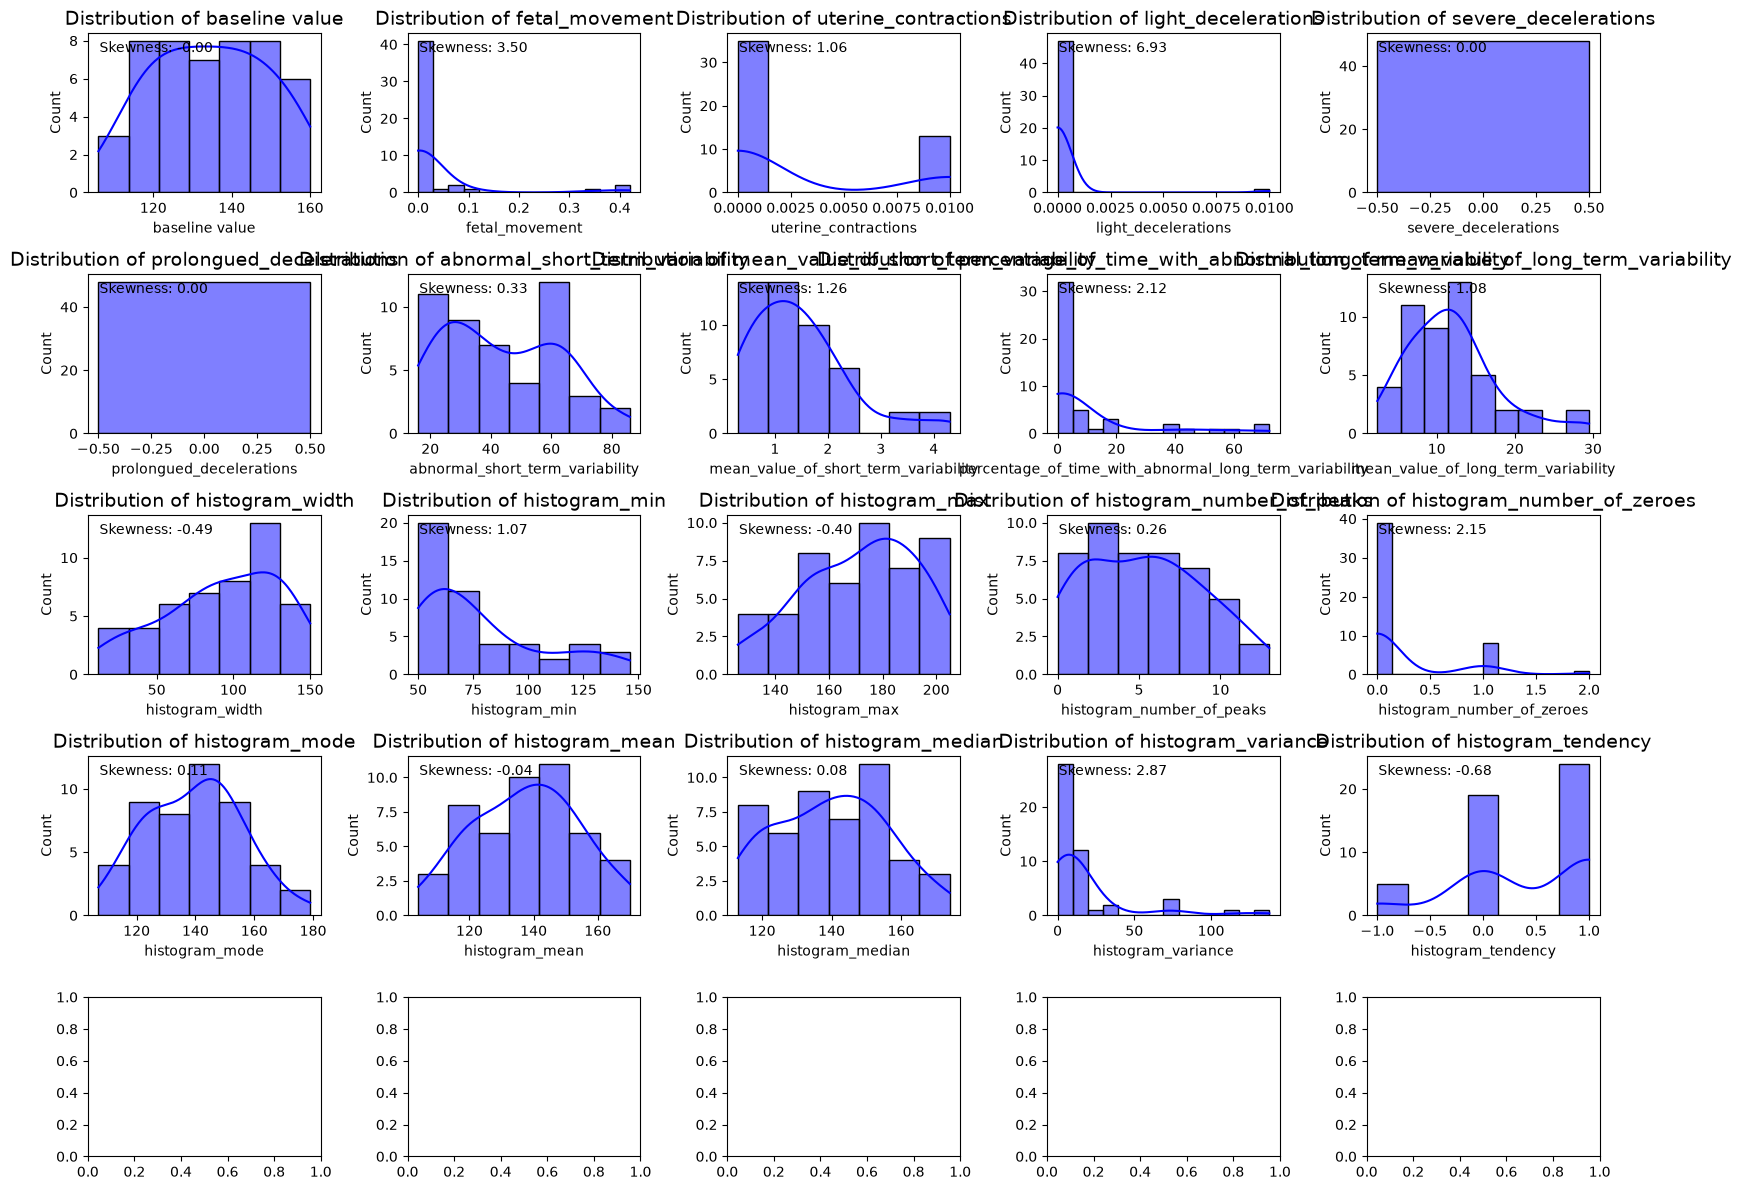

In [60]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
fig,axes = plt.subplots(5, 5, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='blue')
    axes[i].set_title(f'Distribution of {col}', fontsize=14)
    skew = df[col].skew()
    axes[i].text(0.05, 0.95, f'Skewness: {skew:.2f}', transform=axes[i].transAxes, verticalalignment='top')

plt.tight_layout()
plt.show()

4.2 Numeric Variables — Boxplots (Spread & Outliers)

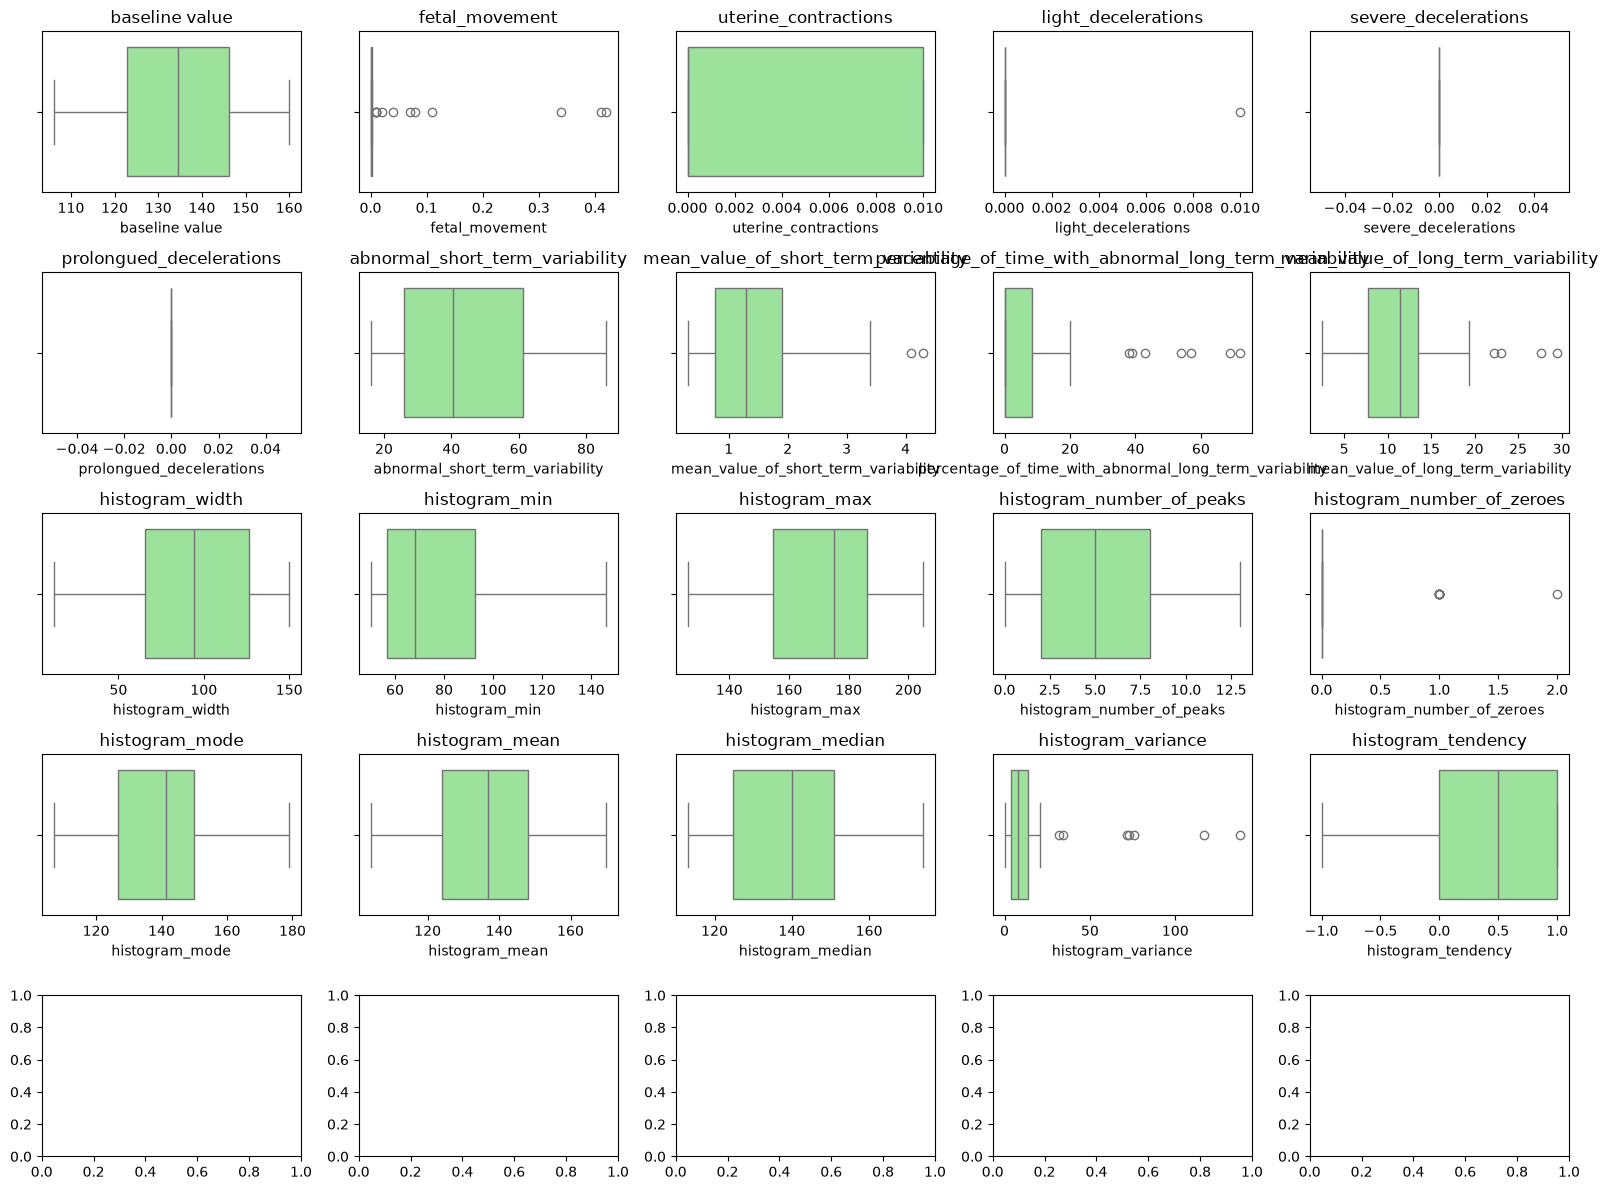

In [64]:
fig, axes = plt.subplots(5, 5, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

   

4.3 Skewness & Kurtosis Summary

In [65]:
stats_df = pd.DataFrame({
    'mean' : df[numeric_cols].mean(),
    'median' : df[numeric_cols].median(),
    'std' : df[numeric_cols].std(),
    'skew' : df[numeric_cols].skew(),
    'kurtosis' : df[numeric_cols].kurtosis()
}).round(2)
stats_df

,mean,median,std,skew,kurtosis
baseline value,134.56,134.5,14.66,-0.00,-1.02
fetal_movement,0.03,0.0,0.10,3.50,11.40
uterine_contractions,0.00,0.0,0.00,1.06,-0.91
light_decelerations,0.00,0.0,0.00,6.93,48.00
severe_decelerations,0.00,0.0,0.00,0.00,0.00
prolongued_decelerations,0.00,0.0,0.00,0.00,0.00
abnormal_short_term_variability,43.69,40.5,19.10,0.33,-1.00
mean_value_of_short_term_variability,1.45,1.3,0.93,1.26,1.79
percentage_of_time_with_abnormal_long_term_variability,10.10,0.0,19.25,2.12,3.50
mean_value_of_long_term_variability,11.92,11.4,5.75,1.08,1.55


4.4 Categorical Variables — Frequency Distributions

KeyError: 'uterine_activity'

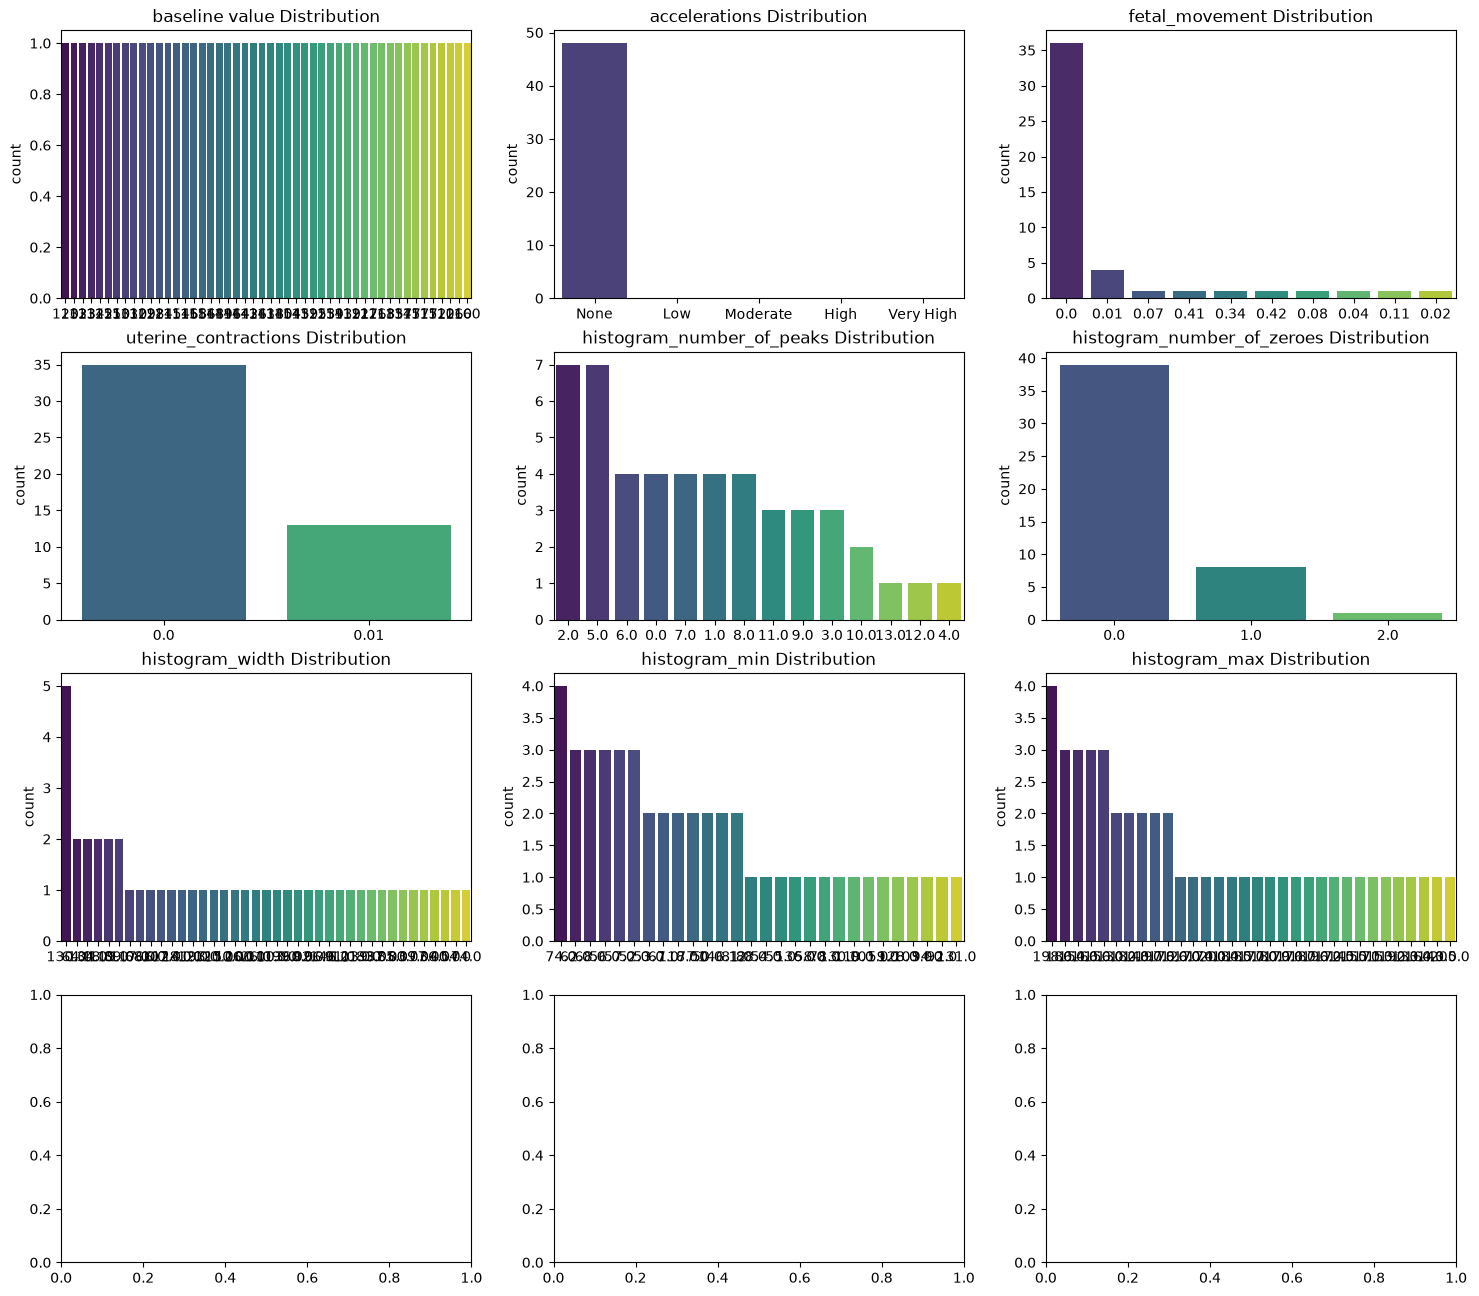

In [66]:
cat_cols = ['baseline value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_width', 'histogram_min', 'histogram_max', 'uterine_activity', 'fetal_health']
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    order = df[col].value_counts().index
    sns.countplot(x=df[col], ax=axes[i], order=order, palette='viridis')
    axes[i].set_title(f'{col} Distribution')
    axes[i].set_xlabel('')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

4.5 Target Variable Balance

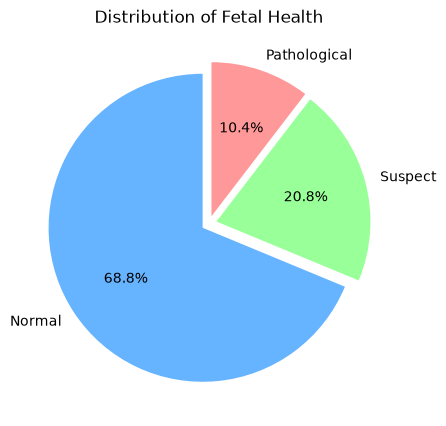

fetal_health
Normal          33
Suspect         10
Pathological     5
Name: count, dtype: int64


In [67]:
plt.figure(figsize=(5,5))
counts = df['fetal_health'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#66b3ff','#99ff99','#ff9999'], startangle=90, explode=(0.05, 0.05, 0.05))
plt.title('Distribution of Fetal Health')
plt.show()      
print(counts)

5. Bivariate Analysis


5.1 Numeric vs Target — Boxplots

IndexError: index 12 is out of bounds for axis 0 with size 12

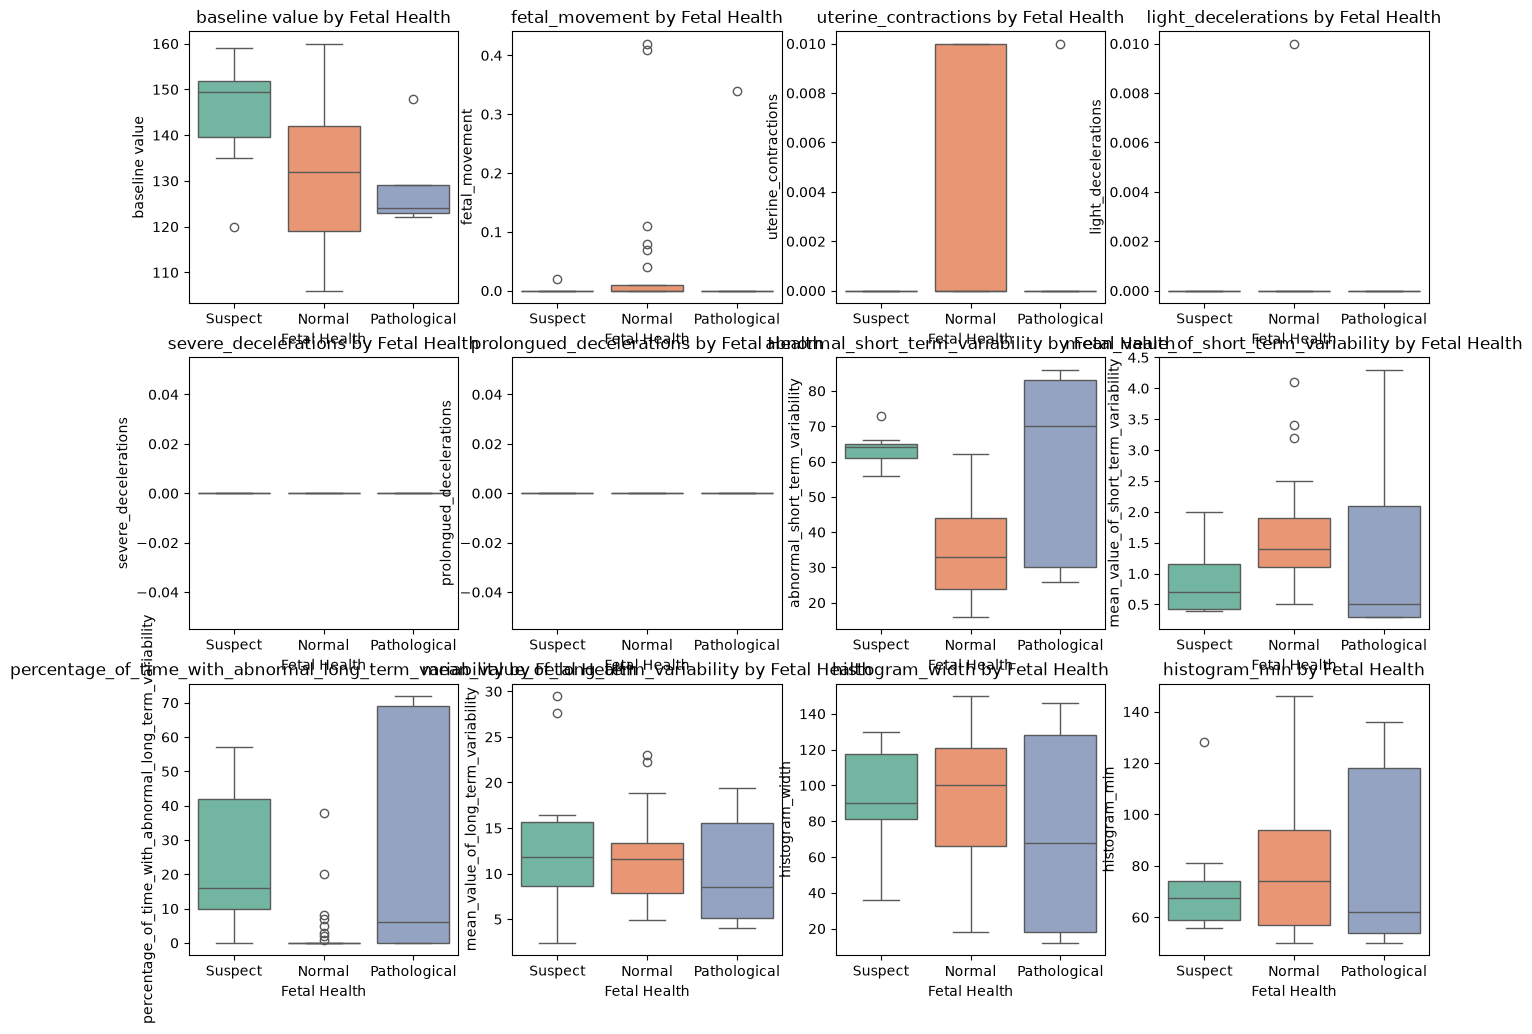

In [68]:
fig,axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.boxplot(x='fetal_health', y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{col} by Fetal Health')
    axes[i].set_xlabel('Fetal Health')
    axes[i].set_ylabel(col)
plt.tight_layout()
plt.show()